# 18 · 작은 U-Net으로 화소마다 분류하기

**이번 질문:** 흐린 도형 사진에서 어느 화소가 물체인지 표시하려면, 작게 줄여 넓게 본 정보와 원래 위치의 세부 정보를 어떻게 합쳐야 할까요?

합성곱으로 특징을 만들고 해상도를 줄이는 encoder, 해상도를 되돌리는 decoder, 같은 해상도의 특징을 채널로 붙이는 skip을 NumPy로 연결합니다. 모든 파라미터와 입력의 backward를 중심차분으로 검산하고 작은 도형을 실제로 학습합니다.

> **용어** · **encoder**는 입력을 더 작은 격자의 특징으로 바꾸는 부분이고, **decoder**는 그 특징의 해상도를 되돌려 화소별 출력을 만드는 부분입니다. **NCHW**는 배열의 축을 배치 수 N, 채널 C, 높이 H, 너비 W 순서로 둔다는 뜻입니다.

- 준비물: [05 CNN](../01_아키텍처/05_cnn.ipynb)의 패치·합성곱 backward, [03 MLP](../00_기초/03_perceptron_to_mlp.ipynb)의 연쇄법칙, [02 손실](../00_기초/02_probability_and_losses.ipynb)의 BCE, [04 optimizer](../00_기초/04_optimizers.ipynb)의 Adam, [15 평가](../02_연결/15_experiments_evaluation.ipynb)의 분할·설정 고정.
- 도착점: 화소별 logit·BCE·soft Dice를 구현하고, 홀수 해상도·빈 mask·skip의 두 기울기 경로를 확인합니다. 다른 노트북의 실행 상태는 필요하지 않습니다.
- 연결: 17의 **더하는 잔차**와 여기의 **채널로 붙이는 skip**은 다른 연산입니다. 18b 물체 검출은 상자 단위로, 이 노트북은 화소 단위로 정답을 만듭니다.

**교육용으로 줄인 구조입니다.** 해상도를 한 번만 줄이고, 같은 크기 padding 합성곱·평균 풀링·최근접 확대·tanh를 사용합니다. 원 논문의 전체 U-Net, valid 합성곱 뒤 crop, 학습되는 up-convolution을 그대로 복제한 구현이 아닙니다. 핵심은 encoder–decoder와 같은 해상도의 특징 연결입니다. [Ronneberger 외, U-Net 원문](https://arxiv.org/abs/1505.04597).

### 읽는 법

| 표시 | 뜻 | 어떻게 읽나 |
|---|---|---|
| 🔑 핵심 | 설명·수식·구현 | 코드를 가리고 같은 계산을 다시 씁니다 |
| 🔍 확인 | 그림·검산 해석 | 실제 결과와 예상을 대조합니다 |
| 📎 참고 | 환경·용어·코드 | 필요한 자리에서 찾아봅니다 |
| ✏️ 연습 | 핵심 한두 줄과 검사 | 정답을 접고 직접 채워 봅니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 입력·mask·logit은 모두 공간 좌표 $(H,W)$를 유지합니다. 마지막 채널 1은 전경 확률 하나를 나타냅니다.
2. downsample은 2×2의 평균, upsample은 복사입니다. backward는 평균 계수 1/4의 배분과 복사한 자리의 합입니다. concatenate의 backward는 채널 분할이고, encoder에는 두 경로의 기울기를 더합니다.
3. BCE는 화소별 분류 목적이고 soft Dice는 이미지별 겹침을 부드럽게 잰 목적입니다. threshold 뒤 hard IoU·Dice는 평가용이며 직접 미분하지 않습니다.

| 기호 | shape | 뜻 |
|---|---|---|
| $X,Y,Z,p$ | $(N,1,H,W)$ | 입력, 이진 정답, logit, 전경 확률 |
| $E$ | $(N,C_e,H,W)$ | encoder의 자세한 위치 정보 |
| $B$ | $(N,C_b,\lceil H/2\rceil,\lceil W/2\rceil)$ | 줄인 해상도의 특징 |
| $U$ | $(N,C_b,H,W)$ | 확대하고 원래 크기로 자른 특징 |
| $[E,U]$ | $(N,C_e+C_b,H,W)$ | 채널로 붙인 decoder 입력 |

[전체 경로](../../docs/CURRICULUM.md) · [글 규칙](../../docs/WRITING.md) · [그림 설계](../../docs/DESIGN.md) · [그림 보조 코드](../../src/utils/unet_plots.py)

In [1]:
# 준비 셀: 실행만 하고 넘어가도 됩니다.
import sys
from pathlib import Path
import time
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/utils/plotting.py").is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.utils import setup_plots, run_check
from src.utils.gradcheck import numerical_gradient, rel_error
from src.utils.unet_plots import (
    plot_pixel_task, plot_resize_coordinates, plot_skip_channels, plot_unet_trace,
    plot_pixel_losses, plot_segmentation_plan, plot_training_curves,
    plot_segmentation_predictions, plot_resolution_variants,
)
setup_plots()
print("NumPy", np.__version__, "· CPU float64 · NCHW 축 순서")

NumPy 2.4.6 · CPU float64 · NCHW 축 순서


### 📎 예시와 학습 계획

노이즈가 있는 원·직사각형을 본문에서 만듭니다. train 96장, validation 24장, test 32장은 서로 다른 seed를 사용합니다. 학습은 160스텝, 배치 8장, Adam 학습률 .015, 목적은 BCE + .5 soft Dice로 미리 고정합니다. test를 보고 설정을 고르지 않습니다.

첫 그림은 계산을 설명하는 7×7 도형이며 마지막 학습은 16×16입니다. 15×17의 홀수 해상도와 전경 비율 변형은 기본 학습 뒤 별도 진단으로 보고합니다. MNIST를 억지로 분할 문제로 바꾸지 않고, 정답 mask를 정확히 아는 도형을 사용합니다.

## 🔑 1. 이미지 하나의 분류를 화소별 분류로 바꿉니다

**이 절에서 가져갈 것:** 전경인지 아닌지 묻는 정답을 모든 화소에 두고 같은 위치의 logit·확률과 비교합니다.

사진 전체에 "원이다"라는 라벨 하나를 붙이면 어느 위치에 원이 있는지 알 수 없습니다. 여기서는 도형 안이면 $Y_{nhw}=1$, 밖이면 0으로 둡니다. 입력의 밝기를 그대로 복원하는 문제와도 다릅니다. 노이즈가 있는 입력에서 깨끗한 **의미의 mask**를 예측합니다.

$$p_{nhw}=\sigma(Z_{nhw}),\qquad \hat Y_{nhw}=1[p_{nhw}\ge0.5]=1[Z_{nhw}\ge0].$$

$Z$는 확률이 아닌 실수 점수이고, 정답과 예측 확률의 shape는 $(N,1,H,W)$입니다. 마지막 축의 위치를 섞으면 다른 화소의 정답과 비교하게 됩니다.

> **용어**
>
> - **분할(segmentation):** 각 화소가 어떤 종류인지 표시하는 문제입니다. 여기서는 전경·배경 두 종류입니다.
> - **mask:** 전경 1·배경 0을 같은 공간 좌표에 적은 배열입니다.
> - **전경(foreground):** 찾으려는 물체가 차지한 화소이고 나머지는 배경입니다.
> - **logit:** sigmoid에 넣기 전의 실수 점수입니다. 양수이면 전경 확률이 .5보다 큽니다.
> - **sigmoid:** 실수 $z$를 $1/(1+e^{-z})$로 바꾸어 0과 1 사이의 확률로 만드는 함수입니다.

> **코드** · `yy, xx = np.mgrid[:H, :W]`는 각각 행 번호와 열 번호를 담은 두 $(H,W)$ 배열입니다. 각 칸에서 중심과의 거리를 계산해 원의 안팎을 판정합니다. `np.clip(a, 0, 1)`은 범위 밖의 밝기를 경계값으로 잘라 줍니다.

In [2]:
scene_y, scene_x = np.mgrid[:7, :7]
scene_mask = (((scene_y-3)**2 + (scene_x-3)**2) <= 5).astype(float)
scene_image = np.clip(.15 + .65*scene_mask + np.random.default_rng(180).normal(0, .15, (7, 7)), 0, 1)
scene_logits = 5*(scene_image-.5)
scene_probability = 1/(1+np.exp(-scene_logits))

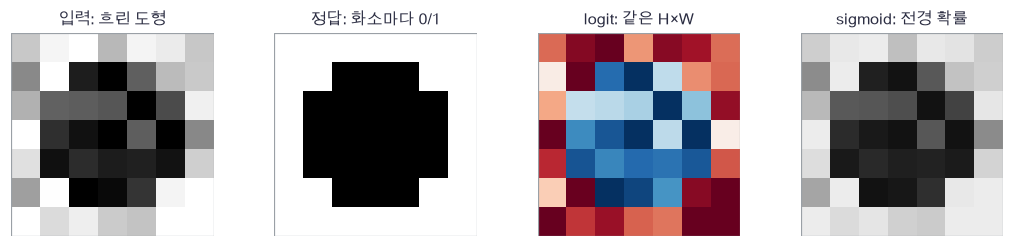

In [3]:
plot_pixel_task(scene_image, scene_mask, scene_logits, scene_probability)

🔍 **확인** · 네 그림은 같은 공간 좌표입니다. 여기의 logit은 밝기에서 손으로 만든 설명용 점수이며 학습 결과가 아닙니다. 실제 모델도 출력 위치를 입력과 맞추되, 주변 화소를 합성곱으로 함께 읽습니다.

> **코드** · `np.where(condition, a, b)`는 조건이 참인 자리에서 a, 거짓인 자리에서 b를 선택합니다. 두 후보 배열은 먼저 계산되므로, 아래 sigmoid는 두 분기 모두 안전하도록 $e^{-|z|}$를 공유합니다. `rng = np.random.default_rng(seed)`는 다른 난수 생성기와 독립적인 난수 상태를 만듭니다.

In [4]:
def sigmoid(logits):
    """안정적인 sigmoid. logits: 어떤 shape → 같은 shape의 [0,1] 확률."""
    exponential = np.exp(-np.abs(logits))
    return np.where(logits >= 0, 1/(1+exponential), exponential/(1+exponential))

In [5]:
def make_shapes(count, height, width, seed, size_scale=1., empty_probability=.15):
    """원·직사각형의 noisy 입력과 이진 mask. → X,Y: (count,1,height,width)."""
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[:height, :width]
    targets = np.zeros((count, 1, height, width))
    for n in range(count):
        if rng.random() < empty_probability:
            continue
        cy, cx = rng.uniform(.25, .75, size=2)*np.array([height-1, width-1])
        radius = rng.uniform(.15, .28)*min(height, width)*size_scale
        if rng.random() < .5:
            mask = (yy-cy)**2+(xx-cx)**2 <= radius**2
        else:
            mask = (np.abs(yy-cy) <= radius) & (np.abs(xx-cx) <= .8*radius)
        targets[n, 0] = mask
    noise = rng.normal(0, .22, size=targets.shape)
    inputs = np.clip(.15+.65*targets+noise, 0, 1)
    return inputs, targets

In [6]:
# 쓰는 것: scene_logits (1절) · scene_probability (1절)
np.testing.assert_allclose(sigmoid(scene_logits), scene_probability)  # 검산: 개념 그림의 확률과 같음
np.testing.assert_allclose(sigmoid(np.array([-1000., 0., 1000.])), [0., .5, 1.])  # 검산: 극단 점수에서도 유한 확률
example_X, example_Y = make_shapes(3, 7, 9, 181)
assert example_X.shape == example_Y.shape == (3, 1, 7, 9), "입력과 mask의 모든 축이 같아야 합니다"
assert set(np.unique(example_Y)) <= {0., 1.}, "정답 mask는 이진 값이어야 합니다"
empty_X, empty_Y = make_shapes(2, 5, 7, 182, empty_probability=1.)
np.testing.assert_array_equal(empty_Y, 0.)  # 검산: 빈 mask도 명시적으로 생성 가능
print("shape·확률·이진/빈 mask 검산 통과")

shape·확률·이진/빈 mask 검산 통과


### ✏️ 연습 1 · 확률을 만들지 않고 같은 hard mask 얻기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

sigmoid가 .5 이상인 조건은 logit이 0 이상인 조건과 같습니다. `logits:(N,1,H,W)`에서 같은 모양의 0/1 mask를 만드세요. 정확히 0인 점수는 전경으로 판정합니다.

In [7]:
def exercise_hard_mask(logits):
    """연습 1: logit의 임계값 판정. logits: (N,1,H,W) → mask: 같은 shape, 0/1."""
    ### 구현할 내용: logits >= 0의 비교를 float 배열로 바꿉니다.
    raise NotImplementedError
    return mask

In [8]:
def check_hard_mask(candidate):
    """음수·0·양수의 위치와 배치 축 보존을 확인합니다."""
    logits = np.array([[[[-2., 0., 3.]]], [[[1., -1., -3.]]]])
    actual = candidate(logits)
    assert actual.shape == logits.shape, "모든 공간·배치 축을 유지해야 합니다"
    np.testing.assert_array_equal(actual, [[[[0., 1., 1.]]], [[[1., 0., 0.]]]])  # 검산: logit 0은 전경
    print("hard mask: 위치별 손계산과 일치합니다.")

run_check(check_hard_mask, exercise_hard_mask, hint="mask = (logits >= 0).astype(float)")

☐ exercise_hard_mask: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: mask = (logits >= 0).astype(float)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mask = (logits >= 0).astype(float)
```

</details>

## 🔑 2. 줄인 격자와 확대한 격자의 좌표를 맞춥니다

**이 절에서 가져갈 것:** 홀수 크기의 처리 규칙을 먼저 정하고, 평균은 배분하고 복사는 합하는 backward를 구현합니다.

3×3을 2×2 창으로 줄이면 마지막 행·열이 남습니다. 이 노트북은 **아래·오른쪽에 0 한 줄만** 덧대어 4×4로 만든 뒤 평균냅니다. 경계에서도 **padding 0을 포함한 네 칸이 분모 4**입니다. padding을 뺀 실제 칸 수로 나누는 평균과 다릅니다.

$$P_{ij}=\frac14\sum_{a,b\in\{0,1\}}E^{pad}_{2i+a,2j+b},\qquad
U_{hw}=B_{\lfloor h/2\rfloor,\lfloor w/2\rfloor}.$$

풀링 결과 크기는 $(\lceil H/2\rceil,\lceil W/2\rceil)$입니다. decoder에서는 각 값을 2×2로 복사하고 **왼쪽 위를 기준으로 원래 $H,W$까지만** 남깁니다. 확대 backward는 잘려 나간 부분을 0 기울기로 복원한 뒤 같은 원본 칸에서 복사된 기여를 합칩니다. 풀링 backward는 1/4씩 네 칸에 나누고 padding에 해당하는 자리는 버립니다.

> **용어** · **최근접 확대(nearest upsampling)**는 새 위치에서 가장 가까운 기존 격자 값을 복사하는 것입니다. 여기서는 정확히 각 칸을 2×2로 복사하는 규칙을 사용합니다.

In [9]:
resize_original = np.arange(1., 10.).reshape(3, 3)
resize_padded = np.pad(resize_original, ((0, 1), (0, 1)))
resize_pooled = resize_padded.reshape(2, 2, 2, 2).mean(axis=(1, 3))
resize_restored = np.repeat(np.repeat(resize_pooled, 2, axis=0), 2, axis=1)[:3, :3]
resize_upstream_padded = np.zeros((4, 4))
resize_upstream_padded[:3, :3] = 1.
resize_counts = resize_upstream_padded.reshape(2, 2, 2, 2).sum(axis=(1, 3))

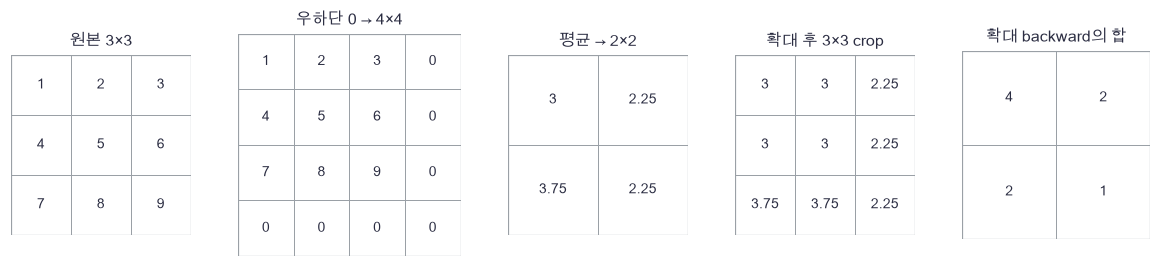

In [10]:
plot_resize_coordinates(resize_original, resize_padded, resize_pooled, resize_restored, resize_counts)

🔍 **확인** · 오른쪽 아래 평균은 $9/4=2.25$입니다. 확대했다가 3×3으로 자르면 왼쪽 위 칸은 네 번, 오른쪽 아래 칸은 한 번만 남습니다. 따라서 출력의 기울기가 모두 1일 때 확대 backward는 4·2·2·1을 돌려줍니다. 경계 규칙은 값뿐 아니라 미분도 바꿉니다.

> **코드** · `reshape(N,C,h,2,w,2)`는 작은 격자 위치와 각 2×2 블록 내부 축을 나눕니다. `mean(axis=(3,5))`는 내부 두 축만 평균냅니다. `np.repeat(..., 2, axis=2)`는 높이 칸을 두 번씩 복사합니다.

In [11]:
def downsample(X):
    """우하단 0 padding 뒤 2×2 평균. X:(N,C,H,W) → (P:(N,C,ceil(H/2),ceil(W/2)), 원래 shape)."""
    N, C, H, W = X.shape
    padded = np.pad(X, ((0, 0), (0, 0), (0, H % 2), (0, W % 2)))
    small_h, small_w = padded.shape[2]//2, padded.shape[3]//2
    return padded.reshape(N, C, small_h, 2, small_w, 2).mean(axis=(3, 5)), X.shape

In [12]:
def downsample_backward(G, original_shape):
    """평균의 기울기를 1/4씩 복사하고 padding 부분 제거. G: 작은 격자 → 원래 shape."""
    H, W = original_shape[2:]
    expanded = np.repeat(np.repeat(G, 2, axis=2), 2, axis=3) / 4
    return expanded[:, :, :H, :W]

In [13]:
def upsample(X, output_hw):
    """2×2 최근접 복사 후 왼쪽 위 기준 crop. X:(N,C,h,w), output_hw:(H,W) → (U, cache)."""
    H, W = output_hw
    assert H <= 2*X.shape[2] and W <= 2*X.shape[3], "두 배 확대 범위 안의 크기여야 합니다"
    expanded = np.repeat(np.repeat(X, 2, axis=2), 2, axis=3)
    return expanded[:, :, :H, :W], (X.shape, output_hw)

In [14]:
def upsample_backward(G, cache):
    """crop된 자리의 기울기를 0으로 되돌린 뒤 복사된 네 칸을 합합니다."""
    (N, C, h, w), (H, W) = cache
    padded = np.zeros((N, C, 2*h, 2*w))
    padded[:, :, :H, :W] = G
    return padded.reshape(N, C, h, 2, w, 2).sum(axis=(3, 5))

In [15]:
def downsample_loop(X):
    """2×2 평균을 좌표 반복으로 계산합니다. X:(N,C,H,W) → (N,C,ceil(H/2),ceil(W/2))."""
    N, C, H, W = X.shape
    output = np.zeros((N, C, (H+1)//2, (W+1)//2))
    for n in range(N):
        for c in range(C):
            for i in range(output.shape[2]):
                for j in range(output.shape[3]):
                    for dy in range(2):
                        for dx in range(2):
                            y, x = 2*i+dy, 2*j+dx
                            if y < H and x < W:
                                output[n, c, i, j] += X[n, c, y, x]/4
    return output

In [16]:
# 쓰는 것: downsample (2절) · downsample_backward (2절) · resize_counts (2절) · resize_original (2절) · resize_restored (2절)
pooled_hand, pool_cache = downsample(resize_original[None, None])
np.testing.assert_allclose(pooled_hand[0, 0], [[3., 2.25], [3.75, 2.25]])  # 검산: padding도 분모 4에 포함
np.testing.assert_allclose(downsample_loop(resize_original[None, None]), pooled_hand)  # 검산: 3×3 손계산·반복문·벡터화 일치
up_hand, up_cache = upsample(pooled_hand, (3, 3))
np.testing.assert_allclose(up_hand[0, 0], resize_restored)  # 검산: 그림의 복사 후 crop
np.testing.assert_allclose(upsample_backward(np.ones_like(up_hand), up_cache)[0, 0], resize_counts)  # 검산: 각 원본 칸의 복사 횟수
np.testing.assert_allclose(downsample_backward(np.ones_like(pooled_hand), pool_cache), .25)  # 검산: 모든 원본 칸에 1/4
resize_rng = np.random.default_rng(183)
resize_probe = resize_rng.normal(size=(1, 2, 3, 5))
resize_small, resize_cache = downsample(resize_probe)
np.testing.assert_allclose(downsample_loop(resize_probe), resize_small)  # 검산: 3×5의 홀수 너비·채널 2개도 같은 평균
resize_G = resize_rng.normal(size=resize_small.shape)
np.testing.assert_allclose(np.sum(resize_small*resize_G), np.sum(resize_probe*downsample_backward(resize_G, resize_cache)))  # 검산: 선형 downsample의 내적 항등식
resize_up, resize_up_cache = upsample(resize_small, (3, 5))
resize_up_G = resize_rng.normal(size=resize_up.shape)
np.testing.assert_allclose(np.sum(resize_up*resize_up_G), np.sum(resize_small*upsample_backward(resize_up_G, resize_up_cache)))  # 검산: crop된 확대의 내적 항등식
print("홀수 좌표·padding 분모·확대 누적 검산 통과")

홀수 좌표·padding 분모·확대 누적 검산 통과


### ✏️ 연습 2 · crop 뒤 남은 복사 기여만 합치기

작은 입력의 shape와 crop된 상류 기울기를 받습니다. 잘린 자리의 기울기는 아래에서 0으로 준비했습니다. 작은 격자와 2×2 내부 축으로 나눠 내부 축을 합하는 한 줄을 채우세요.

In [17]:
def exercise_upsample_gradient(G, small_shape):
    """연습 2: 2배 확대의 backward. G:(N,C,H,W), small_shape:(N,C,h,w) → dsmall."""
    N, C, h, w = small_shape
    padded = np.zeros((N, C, 2*h, 2*w))
    padded[:, :, :G.shape[2], :G.shape[3]] = G
    ### 구현할 내용: reshape(N,C,h,2,w,2) 뒤 내부 축 3·5를 합합니다.
    raise NotImplementedError
    return dsmall

In [18]:
def check_upsample_gradient(candidate):
    """홀수 출력과 한 칸 출력의 복사 개수를 셉니다."""
    actual = candidate(np.ones((1, 1, 3, 3)), (1, 1, 2, 2))
    np.testing.assert_array_equal(actual, [[[[4., 2.], [2., 1.]]]])  # 검산: crop 뒤 남은 복사 개수
    np.testing.assert_array_equal(candidate(np.ones((1, 1, 1, 1)), (1, 1, 1, 1)), 1.)  # 검산: 남은 한 칸만 합함
    print("확대 backward: 손계산과 일치합니다.")

run_check(check_upsample_gradient, exercise_upsample_gradient, hint="dsmall = padded.reshape(N,C,h,2,w,2).sum(axis=(3,5))")

☐ exercise_upsample_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: dsmall = padded.reshape(N,C,h,2,w,2).sum(axis=(3,5))


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dsmall = padded.reshape(N, C, h, 2, w, 2).sum(axis=(3, 5))
```

</details>

## 🔑 3. skip을 채널로 붙이고 역방향에서는 나눕니다

**이 절에서 가져갈 것:** concatenate는 채널을 늘리는 연산이며, encoder 기울기는 줄인 경로와 직접 skip 경로를 더한 값입니다.

작은 격자의 한 칸은 넓은 영역을 보지만 원래 경계 위치는 흐려질 수 있습니다. decoder에 encoder의 같은 좌표 특징을 바로 보내면 자세한 위치와 넓은 문맥을 함께 읽을 수 있습니다.

$$E=\tanh(C_e(X)),\quad B=\tanh(C_b(\mathrm{down}(E))),\quad U=\mathrm{up}(B),\quad
A=\tanh(C_d([E,U])),\quad Z=C_o(A).$$

$C_e,C_b,C_d$는 3×3 same 합성곱, $C_o$는 1×1 합성곱입니다. `[E,U]`는 더하기가 아니라 채널 축 연결입니다. 기본 채널 수는 3→4→3→1이고, decoder 입력 채널은 3+4=7입니다.

$$d[E,U]=[dE_{skip},dU],\qquad dE=dE_{down}+dE_{skip},\qquad
dZ_e=dE\odot(1-E^2).$$

backward에서 앞 $C_e$채널을 skip으로, 나머지를 확대 경로로 보냅니다. 그 다음 encoder의 두 경로를 합친 뒤 tanh의 미분을 한 번 곱합니다. 작은 probe에서는 모든 값이 매끄러운 tanh이므로 중심차분과 직접 대조하기 쉽습니다.

> **용어** · **concatenate**는 같은 공간 좌표의 채널들을 차례로 붙이는 연산입니다. 두 입력의 채널 수가 달라도 되지만 $N,H,W$는 같아야 합니다.

In [19]:
skip_demo_E = np.array([[1., 2.], [3., 4.]])
skip_demo_U = np.array([[10., 20.]])
skip_demo_joined = np.concatenate([skip_demo_E, skip_demo_U], axis=0)
skip_demo_G = np.array([[.1, .2], [.3, .4], [.5, .6]])
skip_demo_dE, skip_demo_dU = skip_demo_G[:2], skip_demo_G[2:]

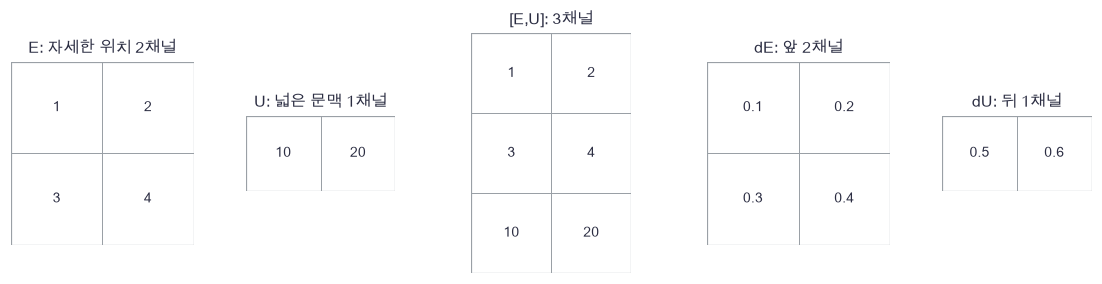

In [20]:
plot_skip_channels(skip_demo_E, skip_demo_U, skip_demo_joined, skip_demo_dE, skip_demo_dU)

🔍 **확인** · 각 행을 채널 하나, 각 열을 공간 위치 하나로 그렸습니다. 2채널과 1채널을 붙이면 3채널이고, backward는 같은 경계에서 나눕니다. 채널을 더해 버리면 서로 다른 특징의 정체성과 이 분할 규칙이 사라집니다.

아래 conv는 05번과 같은 패치 행렬 곱입니다. 패치를 행으로 쌓으면 $O=PW^T+b$, backward는 $dW=dO^TP$, $dP=dOW$이고 겹친 입력 위치에 `+=`로 누적합니다. 모든 커널은 홀수 크기이며 같은 크기 padding만 지원합니다.

> **코드** · `sliding_window_view(X,(k,k),axis=(2,3))`는 공간마다 커널 창을 읽는 배열을 만듭니다. `transpose(0,2,3,1,4,5)`는 (N,H,W,C,k,k)로 축을 옮겨 한 창을 한 행으로 펼칠 준비를 합니다.

In [21]:
def conv_forward(X, W, b):
    """stride1 same conv. X:(N,C,H,W), W:(F,C,k,k), b:(F,) → (O:(N,F,H,W), cache)."""
    N, C, H, width = X.shape
    F, _, k, _ = W.shape
    padding = k//2
    padded = np.pad(X, ((0, 0), (0, 0), (padding, padding), (padding, padding)))
    windows = sliding_window_view(padded, (k, k), axis=(2, 3))
    patches = windows.transpose(0, 2, 3, 1, 4, 5).reshape(-1, C*k*k)
    output = patches @ W.reshape(F, -1).T + b
    return output.reshape(N, H, width, F).transpose(0, 3, 1, 2), (X.shape, W, patches)

In [22]:
def conv_backward(G, cache):
    """패치 행렬곱 backward와 겹침 누적. G:(N,F,H,W) → (dX, dW, db)."""
    (N, C, H, width), W, patches = cache
    F, _, k, _ = W.shape
    padding = k//2
    flat_G = G.transpose(0, 2, 3, 1).reshape(-1, F)
    dW = (flat_G.T @ patches).reshape(W.shape)
    db = flat_G.sum(axis=0)
    patch_G = (flat_G @ W.reshape(F, -1)).reshape(N, H, width, C, k, k).transpose(0, 3, 1, 2, 4, 5)
    padded_G = np.zeros((N, C, H+2*padding, width+2*padding))
    for i in range(k):
        for j in range(k):
            padded_G[:, :, i:i+H, j:j+width] += patch_G[:, :, :, :, i, j]
    return padded_G[:, :, padding:padding+H, padding:padding+width], dW, db

In [23]:
def init_unet(seed=184, encoder_channels=3, bottleneck_channels=4, decoder_channels=3):
    """네 합성곱의 파라미터 사전. tanh용 fan-in 척도, bias0, 모든 값 float64."""
    rng = np.random.default_rng(seed)
    shapes = {"e": (encoder_channels, 1, 3, 3), "b": (bottleneck_channels, encoder_channels, 3, 3),
              "d": (decoder_channels, encoder_channels+bottleneck_channels, 3, 3), "o": (1, decoder_channels, 1, 1)}
    parameters = {}
    for name, shape in shapes.items():
        fan_in = np.prod(shape[1:])
        parameters["W"+name] = rng.normal(size=shape) / np.sqrt(fan_in)
        parameters["b"+name] = np.zeros(shape[0])
    return parameters

In [24]:
# 쓰는 것: downsample (2절) · upsample (2절)
def unet_forward(X, parameters, use_skip=True):
    """한 단계 U-Net. X:(N,1,H,W) → logits:(N,1,H,W), backward cache. skip0 대조도 같은 채널 수."""
    e_pre, e_cache = conv_forward(X, parameters["We"], parameters["be"])
    E = np.tanh(e_pre)
    P, pool_cache = downsample(E)
    b_pre, b_cache = conv_forward(P, parameters["Wb"], parameters["bb"])
    B = np.tanh(b_pre)
    U, up_cache = upsample(B, X.shape[2:])
    joined = np.concatenate([E if use_skip else np.zeros_like(E), U], axis=1)
    d_pre, d_cache = conv_forward(joined, parameters["Wd"], parameters["bd"])
    A = np.tanh(d_pre)
    logits, o_cache = conv_forward(A, parameters["Wo"], parameters["bo"])
    cache = (E, B, A, e_cache, pool_cache, b_cache, up_cache, d_cache, o_cache, use_skip)
    return logits, cache

In [25]:
# 쓰는 것: downsample_backward (2절) · upsample_backward (2절)
def unet_backward(G, cache):
    """출력에서 모든 파라미터·입력으로 backward. G:(N,1,H,W) → (dX, gradients 사전)."""
    E, B, A, e_cache, pool_cache, b_cache, up_cache, d_cache, o_cache, use_skip = cache
    gradients = {}
    # 1. 출력층과 decoder를 거슬러 채널 연결 위치까지 갑니다.
    dA, gradients["Wo"], gradients["bo"] = conv_backward(G, o_cache)
    djoined, gradients["Wd"], gradients["bd"] = conv_backward(dA*(1-A**2), d_cache)
    dE_skip, dU = djoined[:, :E.shape[1]], djoined[:, E.shape[1]:]
    # 2. 확대 → bottleneck → 평균 풀링 경로입니다.
    dB = upsample_backward(dU, up_cache)
    dP, gradients["Wb"], gradients["bb"] = conv_backward(dB*(1-B**2), b_cache)
    dE = downsample_backward(dP, pool_cache)
    # 3. 직접 skip 기여를 합친 뒤 encoder tanh와 합성곱을 미분합니다.
    if use_skip:
        dE = dE + dE_skip
    dX, gradients["We"], gradients["be"] = conv_backward(dE*(1-E**2), e_cache)
    return dX, gradients

In [26]:
# 쓰는 것: scene_image (1절)
trace_parameters = init_unet()
trace_logits, trace_cache = unet_forward(scene_image[None, None], trace_parameters)
trace_E, trace_B, trace_A = trace_cache[:3]
trace_labels = [f"E 채널0 · {trace_E.shape[1:]}", f"B 채널0 · {trace_B.shape[1:]}", f"A 채널0 · {trace_A.shape[1:]}", f"logit · {trace_logits.shape[1:]}"]

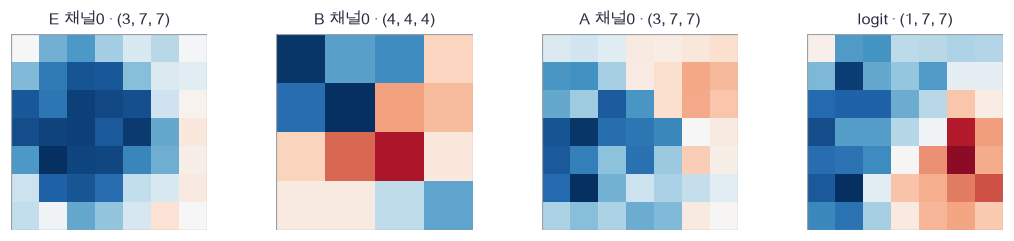

In [27]:
plot_unet_trace(trace_E[0, 0], trace_B[0, 0], trace_A[0, 0], trace_logits[0, 0], trace_labels)

🔍 **확인** · 실제 forward의 첫 채널만 표시했습니다. 7×7이 4×4로 줄었다가 다시 7×7로 돌아옵니다. 이 그림은 아직 학습 전이므로 feature의 모양이나 logit 부호를 정답으로 읽지 않습니다.

검산은 더 작은 $(1,1,3,5)$ 입력과 채널 2·2·2를 씁니다. `sum(logits*probe_G)`라는 스칼라를 만들고 **8개 파라미터 배열의 모든 원소와 입력의 모든 원소**를 중심차분합니다. skip 사용/0 두 경우를 모두 검사합니다.

In [28]:
# 쓰는 것: init_unet (3절) · unet_forward (3절)
def check_unet_gradients(use_skip):
    """홀수3×5 probe에서 전체 파라미터·입력의 수치미분을 검사합니다. 최대 상대오차를 반환합니다."""
    rng = np.random.default_rng(185)
    X = rng.normal(scale=.4, size=(1, 1, 3, 5))
    parameters = init_unet(186, 2, 2, 2)
    logits, cache = unet_forward(X, parameters, use_skip)
    upstream = rng.normal(size=logits.shape)
    dX, gradients = unet_backward(upstream, cache)
    def scalar():
        """검산 목적: 임의의 상류 기울기와 logit의 내적."""
        return float(np.sum(unet_forward(X, parameters, use_skip)[0]*upstream))
    errors = {"X": rel_error(dX, numerical_gradient(scalar, X))}
    for key, value in parameters.items():
        numeric = numerical_gradient(scalar, value)
        errors[key] = rel_error(gradients[key], numeric)
        np.testing.assert_allclose(gradients[key], numeric, atol=2e-8, rtol=2e-6)  # 검산: 모든 원소의 수치미분
    np.testing.assert_allclose(dX, numerical_gradient(scalar, X), atol=2e-8, rtol=2e-6)  # 검산: 입력까지 두 경로가 돌아옴
    if not use_skip:
        np.testing.assert_array_equal(gradients["Wd"][:, :2], 0.)  # 검산: 0 입력 채널에 붙은 가중치 기울기는 0
    assert max(errors.values()) < 2e-6, "전체 배열의 상대오차가 2e-6 아래여야 합니다"
    return errors

In [29]:
full_gradient_errors = check_unet_gradients(True)
zero_gradient_errors = check_unet_gradients(False)
print("skip 사용: 전체 배열 상대오차", full_gradient_errors)
print("skip 0: 전체 배열 상대오차", zero_gradient_errors)

skip 사용: 전체 배열 상대오차

 {'X': 3.835190899053285e-10, 'We': 3.653701744265923e-10, 'be': 5.122874702247576e-11, 'Wb': 4.2527599460438924e-10, 'bb': 2.084494474521972e-11, 'Wd': 6.299948167410177e-11, 'bd': 7.116443020611039e-11, 'Wo': 9.737163396677669e-11, 'bo': 9.05390073378422e-11}
skip 0: 전체 배열 상대오차 {'X': 1.4562074841853623e-10, 'We': 3.82782761815116e-10, 'be': 1.0583114629575029e-11, 'Wb': 1.720151590835329e-10, 'bb': 1.1149556121238897e-11, 'Wd': 6.383116927094688e-11, 'bd': 9.768579142537075e-11, 'Wo': 2.2020535066527278e-11, 'bo': 1.197558030887893e-11}


### ✏️ 연습 3 · 붙인 채널의 기울기를 원래 두 입력으로

`G:(N,C_e+C_b,H,W)`를 encoder 채널 수 `encoder_channels`에서 둘로 나누세요. 높이·너비 축은 그대로 둡니다.

In [30]:
def exercise_split_skip(G, encoder_channels):
    """연습 3: 채널 연결의 backward. G:(N,Ce+Cb,H,W) → dE, dU."""
    ### 구현할 내용: 앞 Ce채널은 dE, 뒤 채널은 dU입니다.
    raise NotImplementedError
    return dE, dU

In [31]:
def check_split_skip(candidate):
    """배치·공간 축을 유지하며 채널만 나누는지 검사합니다."""
    G = np.arange(12.).reshape(1, 3, 2, 2)
    dE, dU = candidate(G, 2)
    assert dE.shape == (1, 2, 2, 2), "encoder 채널 두 개를 남겨야 합니다"
    assert dU.shape == (1, 1, 2, 2), "확대 경로 채널 한 개를 남겨야 합니다"
    np.testing.assert_array_equal(dE.ravel(), np.arange(8.))  # 검산: 앞 여덟 원소
    np.testing.assert_array_equal(dU.ravel(), np.arange(8., 12.))  # 검산: 뒤 네 원소
    print("skip 채널 분할: 손계산과 일치합니다.")

run_check(check_split_skip, exercise_split_skip, hint="dE = G[:, :encoder_channels], dU = G[:, encoder_channels:]")

☐ exercise_split_skip: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: dE = G[:, :encoder_channels], dU = G[:, encoder_channels:]


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dE = G[:, :encoder_channels]
dU = G[:, encoder_channels:]
```

</details>

## 🔑 4. BCE·soft Dice의 목적과 hard 지표를 구분합니다

**이 절에서 가져갈 것:** 화소 평균 BCE와 이미지 평균 soft Dice를 정확한 분모로 미분하고, 빈 mask의 평가 규약을 명시합니다.

물체가 화면의 5%뿐이면 전부 배경이라고 해도 화소 정확도가 95%입니다. BCE는 모든 화소의 분류 비용을 평균내며, soft Dice는 한 이미지 안의 예측 전경과 정답 전경의 겹침을 봅니다. 두 목적은 서로 다른 정보를 주므로 각각 기록합니다.

> **용어** · **BCE(binary cross-entropy, 이진 교차 엔트로피)**는 정답이 1이면 $-\log p$, 0이면 $-\log(1-p)$를 부과하는 이진 분류 손실입니다. 코드에서는 각 화소의 비용을 평균냅니다.

화소 수 $P=HW$, 이미지 $n$에서 $A_n=2\sum_i p_{ni}y_{ni}+s$, $B_n=\sum_i p_{ni}+\sum_i y_{ni}+s$로 놓겠습니다. 이 노트북은 $s=1$, $\lambda=0.5$입니다.

$$L_{BCE}=\frac1{NP}\sum_{n,i}[\log(1+e^{z_{ni}})-y_{ni}z_{ni}],\qquad
L_D=\frac1N\sum_n\left(1-\frac{A_n}{B_n}\right),\quad L=L_{BCE}+\lambda L_D.$$

$$\frac{\partial L_D}{\partial p_{ni}}=\frac{A_n-2y_{ni}B_n}{N B_n^2},\qquad
\frac{\partial L}{\partial z_{ni}}=\frac{p_{ni}-y_{ni}}{NP}+\lambda\frac{A_n-2y_{ni}B_n}{N B_n^2}p_{ni}(1-p_{ni}).$$

Dice는 **이미지별 비율을 낸 뒤 이미지 축을 평균**합니다. 큰 물체 이미지와 작은 물체 이미지가 같은 비중을 가지며, 전체 배치 화소를 합쳐 비율 하나를 내는 방식과 다릅니다. $s$는 분모 0을 막고 빈 mask도 학습하도록 하는 **고정된 평활값**이며, 작고 큰 물체에 미치는 영향이 다를 수 있습니다.

hard 평가는 $\hat y=1[p\ge.5]$로 판정한 뒤 $IoU=I/(S_{pred}+S_y-I)$, $Dice=2I/(S_{pred}+S_y)$를 계산합니다. **예측과 정답이 모두 비면 두 지표를 1**, 한쪽만 비면 0으로 정합니다. 임계값 뒤의 hard 지표는 여기서 미분하지 않습니다.

> **용어** · **IoU**는 교집합을 합집합으로 나눈 비율이고, **Dice**는 교집합의 두 배를 두 집합 크기의 합으로 나눈 비율입니다. **soft Dice**는 예측의 0/1 대신 확률을 넣어 매끄럽게 만든 학습 목적입니다.

In [32]:
loss_demo_y = np.array([[1., 0.], [0., 0.]])
loss_demo_p = np.array([[.8, .3], [.2, .1]])
loss_demo_z = np.log(loss_demo_p/(1-loss_demo_p))
loss_demo_bce = np.logaddexp(0, loss_demo_z)-loss_demo_y*loss_demo_z
loss_demo_A = 2*np.sum(loss_demo_p*loss_demo_y)+1.
loss_demo_B = loss_demo_p.sum()+loss_demo_y.sum()+1.
loss_demo_gp = (loss_demo_A-2*loss_demo_y*loss_demo_B)/loss_demo_B**2
loss_demo_dz = (loss_demo_p-loss_demo_y)/4 + .5*loss_demo_gp*loss_demo_p*(1-loss_demo_p)
loss_demo_values = [loss_demo_bce.mean(), 1-loss_demo_A/loss_demo_B]

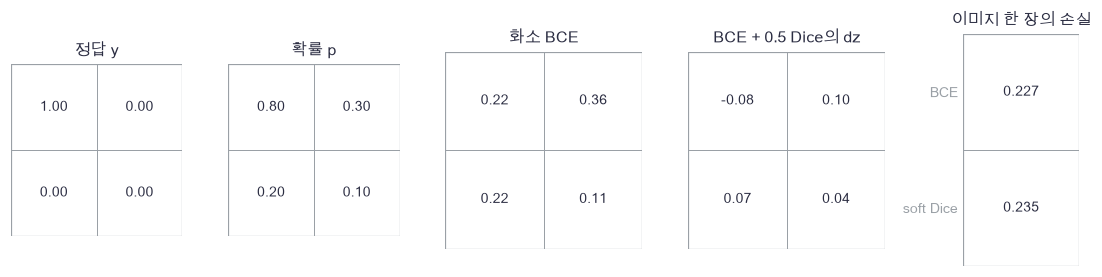

In [33]:
plot_pixel_losses(loss_demo_y, loss_demo_p, loss_demo_bce, loss_demo_dz, loss_demo_values)

🔍 **확인** · 정답 전경 한 칸의 기울기는 확률을 키우는 방향이고 배경 세 칸은 줄이는 방향입니다. soft Dice의 분모에는 같은 이미지의 모든 예측 확률이 들어가므로 한 화소의 기여도 다른 화소의 값에 영향을 받습니다. BCE와 Dice의 수치는 서로 다른 목적의 크기이며 이름을 바꾸어 같은 지표처럼 비교하지 않습니다.

> **코드** · `np.logaddexp(0, z)`는 $\log(1+e^z)$를 큰 양수에서도 안전하게 계산합니다. `sum(axis=(1,2,3), keepdims=True)`는 채널·높이·너비를 합하되 축 길이를 1로 남겨 이미지별 값을 원래 화소에 broadcast합니다. `np.divide(a, b, out=initial, where=b>0)`는 분모가 양수인 자리만 나누고 나머지는 initial 값으로 둡니다. 두 mask가 빈 자리의 지표를 1로 남기면서 0/0 계산도 피할 수 있습니다.

In [34]:
def soft_dice_loss_gradient(probability, target, smooth=1.):
    """이미지별 soft Dice 손실과 확률 미분. p,y:(N,1,H,W) → (평균 loss, dP:같은 shape)."""
    axes = (1, 2, 3)
    numerator = 2*np.sum(probability*target, axis=axes, keepdims=True)+smooth
    denominator = np.sum(probability, axis=axes, keepdims=True)+np.sum(target, axis=axes, keepdims=True)+smooth
    loss = np.mean(1-numerator/denominator)
    gradient = (numerator-2*target*denominator)/(len(target)*denominator**2)
    return float(loss), gradient

In [35]:
# 쓰는 것: sigmoid (1절)
def segmentation_loss(logits, target, dice_weight=.5):
    """안정 BCE + λ soft Dice 및 logit 미분. logits,target:(N,1,H,W) → (loss,dZ,두 항)."""
    probability = sigmoid(logits)
    bce = np.mean(np.logaddexp(0, logits)-target*logits)
    dice, dice_gradient = soft_dice_loss_gradient(probability, target)
    gradient = (probability-target)/target.size + dice_weight*dice_gradient*probability*(1-probability)
    return float(bce+dice_weight*dice), gradient, {"bce": float(bce), "soft_dice": dice}

In [36]:
def hard_scores(probability, target):
    """이미지별 hard IoU·Dice. p,y:(N,1,H,W) → 두 (N,) 배열; 양쪽 빈 mask는 1."""
    prediction = probability >= .5
    truth = target > .5
    intersection = np.sum(prediction & truth, axis=(1, 2, 3))
    pred_size = prediction.sum(axis=(1, 2, 3))
    true_size = truth.sum(axis=(1, 2, 3))
    union = pred_size+true_size-intersection
    total = pred_size+true_size
    iou = np.divide(intersection, union, out=np.ones(len(target)), where=union > 0)
    dice = np.divide(2*intersection, total, out=np.ones(len(target)), where=total > 0)
    return iou, dice

In [37]:
def evaluate_probability(probability, target):
    """화소 정확도·이미지별 IoU/Dice 평균·비어 있지 않은 정답의 IoU를 구분합니다."""
    iou, dice = hard_scores(probability, target)
    nonempty = target.sum(axis=(1, 2, 3)) > 0
    return {"pixel_accuracy": float(np.mean((probability >= .5) == (target > .5))),
            "iou": float(iou.mean()), "dice": float(dice.mean()),
            "nonempty_iou": float(iou[nonempty].mean()) if nonempty.any() else None}

In [38]:
# 쓰는 것: loss_demo_dz (4절) · loss_demo_values (4절) · loss_demo_y (4절) · loss_demo_z (4절) · soft_dice_loss_gradient (4절)
demo_loss, demo_gradient, demo_terms = segmentation_loss(loss_demo_z[None, None], loss_demo_y[None, None])
np.testing.assert_allclose([demo_terms["bce"], demo_terms["soft_dice"]], loss_demo_values)  # 검산: 그림의 두 목적항
np.testing.assert_allclose(demo_gradient[0, 0], loss_demo_dz)  # 검산: 직접 쓴 연쇄법칙
empty_probability = np.zeros((1, 1, 2, 2))
empty_target = np.zeros_like(empty_probability)
np.testing.assert_allclose(soft_dice_loss_gradient(empty_probability, empty_target)[0], 0.)  # 검산: 양쪽 비면 평활 Dice 손실 0
hard_p = np.array([[[[0., 0.]]], [[[1., 0.]]], [[[1., 1.]]]])
hard_y = np.array([[[[0., 0.]]], [[[0., 0.]]], [[[1., 0.]]]])
hard_iou, hard_dice = hard_scores(hard_p, hard_y)
np.testing.assert_allclose(hard_iou, [1., 0., .5])  # 검산: 양쪽 빈 경우, 예측만 존재, 교집합1/합집합2
np.testing.assert_allclose(hard_dice, [1., 0., 2/3])  # 검산: 빈 규약과 2*1/(2+1)
extreme_loss, extreme_grad, extreme_terms = segmentation_loss(np.array([[[[-1000., 1000.]]]]), np.array([[[[1., 0.]]]]))
assert np.isfinite(extreme_loss), "극단 logit도 BCE가 유한해야 합니다"
assert np.all(np.isfinite(extreme_grad)), "극단 logit의 기울기도 유한해야 합니다"
print("손계산·빈 mask·hard 규약·극단 logit 검산 통과")

손계산·빈 mask·hard 규약·극단 logit 검산 통과


In [39]:
loss_probe = np.random.default_rng(187).normal(size=(2, 1, 3, 5))
target_probe = (np.random.default_rng(188).random(loss_probe.shape) > .75).astype(float)
target_probe[0] = 0.

In [40]:
# 쓰는 것: segmentation_loss (4절)
def loss_scalar():
    """검산 목적: 빈 mask가 섞인 배치의 결합 손실."""
    return segmentation_loss(loss_probe, target_probe)[0]

In [41]:
# 쓰는 것: segmentation_loss (4절)
numeric_loss_gradient = numerical_gradient(loss_scalar, loss_probe)
analytic_loss_gradient = segmentation_loss(loss_probe, target_probe)[1]
np.testing.assert_allclose(analytic_loss_gradient, numeric_loss_gradient, atol=1e-8, rtol=2e-6)  # 검산: BCE·Dice·sigmoid·N 평균을 함께 미분
assert rel_error(analytic_loss_gradient, numeric_loss_gradient) < 2e-6, "빈 mask를 포함한 결합 손실 미분이 맞아야 합니다"
print("결합 손실 logit 상대오차:", rel_error(analytic_loss_gradient, numeric_loss_gradient))

결합 손실 logit 상대오차: 6.03411793523394e-09


### ✏️ 연습 4 · soft Dice를 확률까지 미분하기

이미지별 $A=2\sum py+s$, $B=\sum p+\sum y+s$는 아래에서 준비했습니다. $dP=(A-2yB)/(N B^2)$ 한 줄을 채우세요. sigmoid 미분은 아직 곱하지 않습니다.

In [42]:
def exercise_soft_dice_gradient(probability, target, smooth=1.):
    """연습 4: 이미지 평균 soft Dice의 dP. probability,target:(N,1,H,W) → 같은 shape."""
    numerator = 2*np.sum(probability*target, axis=(1, 2, 3), keepdims=True)+smooth
    denominator = np.sum(probability+target, axis=(1, 2, 3), keepdims=True)+smooth
    ### 구현할 내용: (A-2*y*B) / (N*B²)
    raise NotImplementedError
    return gradient

In [43]:
def check_soft_dice_gradient(candidate):
    """A=2, B=3인 손계산과 배치 두 배의 평균 계수를 검사합니다."""
    p = np.array([[[[.5, .5], [0., 0.]]]])
    y = np.array([[[[1., 0.], [0., 0.]]]])
    expected = np.array([[[[-4/9, 2/9], [2/9, 2/9]]]])
    np.testing.assert_allclose(candidate(p, y), expected)  # 검산: (2-2*y*3)/9
    two = candidate(np.repeat(p, 2, axis=0), np.repeat(y, 2, axis=0))
    np.testing.assert_allclose(two, np.repeat(expected/2, 2, axis=0))  # 검산: 두 이미지 평균이면 각 미분이 절반
    print("soft Dice dP: 손계산과 배치 평균이 일치합니다.")

run_check(check_soft_dice_gradient, exercise_soft_dice_gradient, hint="gradient = (numerator-2*target*denominator)/(len(target)*denominator**2)")

☐ exercise_soft_dice_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: gradient = (numerator-2*target*denominator)/(len(target)*denominator**2)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = (numerator-2*target*denominator)/(len(target)*denominator**2)
```

</details>

## 🔑 5. 같은 예산으로 skip의 직접 경로를 비교합니다

**이 절에서 가져갈 것:** 분할·초기값·배치 순서·스텝 수를 고정하고, 구조 차이와 실제 성능·기울기 진단을 구분합니다.

두 모델은 같은 초기 배열과 미니배치를 받습니다. 첫 모델은 `[E,U]`, 대조는 `[0,U]`를 decoder에 전달합니다. 이 **zero-skip 대조**는 같은 배열·연산 shape에서 직접 경로만 끈 실험입니다. encoder를 거쳐 bottleneck으로 가는 경로는 그대로 학습됩니다.

$$J(\theta)=L_{BCE}(Z_\theta,Y)+0.5L_D(\sigma(Z_\theta),Y),\qquad
\theta\leftarrow \mathrm{Adam}(\theta,\nabla_\theta J).$$

zero-skip에서는 `Wd`의 앞 $C_e$ 입력 채널에 연결된 값들이 항상 0 입력을 받습니다. 해당 가중치의 데이터 기울기도 0이므로 **저장된 파라미터 수와 활성 파라미터 수가 다릅니다**. 두 모델의 유효 표현 능력이 완전히 같다는 비교가 아니며, 여러 seed·여러 데이터의 보편적 성능 순위도 아닙니다.

train에서만 갱신하고 validation은 고정된 20스텝마다 진단합니다. 스텝 수·학습률·loss 가중치를 validation이나 test 결과를 본 뒤 변경하지 않습니다. 마지막 test에서 두 모델의 출력과 지표를 한 번 계산해 그림에도 같은 출력을 사용합니다.

In [44]:
# 쓰는 것: init_unet (3절)
TRAIN_COUNT, VALID_COUNT, TEST_COUNT = 96, 24, 32
STEPS, BATCH, LEARNING_RATE = 160, 8, .015
initial_parameters = init_unet(189)
parameter_count = sum(value.size for value in initial_parameters.values())
encoder_channel_count = initial_parameters["We"].shape[0]
inactive_skip_weights = initial_parameters["Wd"][:, :encoder_channel_count].size
active_zero_count = parameter_count-inactive_skip_weights
parameter_plan = np.array([[parameter_count, parameter_count], [parameter_count, active_zero_count]])
sample_budget = [STEPS, BATCH, STEPS*BATCH]

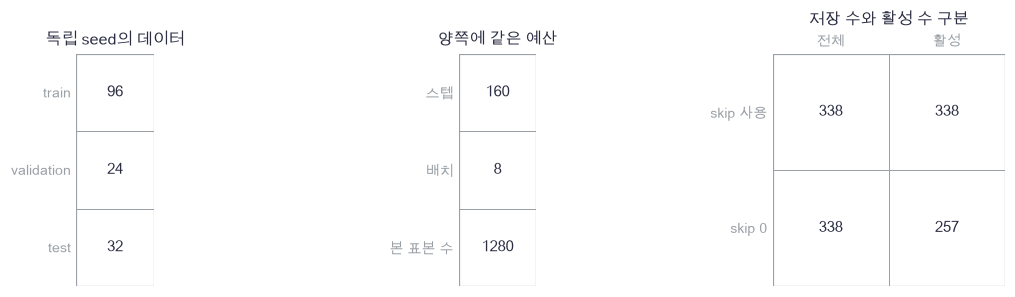

In [45]:
plot_segmentation_plan([TRAIN_COUNT, VALID_COUNT, TEST_COUNT], sample_budget, parameter_plan)

🔍 **확인** · 두 모델 모두 160번 갱신하며 한 번에 8장을 봅니다. 같은 관측을 다시 뽑을 수 있으므로 1,280은 고유 학습 이미지 수가 아니라 **누적 처리 표본 수**입니다. 전체 파라미터는 실제 배열 크기의 합으로 338개이며, zero-skip에서는 그중 81개 입력 연결이 비활성이라 활성 수가 257개입니다.

> **코드** · `{key: value.copy() for key, value in parameters.items()}`는 사전 안의 각 배열까지 복사합니다. 사전만 복사하면 두 모델이 같은 배열을 가리킬 수 있습니다. `rng.integers(0, N, size=(steps, batch))`는 0 이상 N 미만의 인덱스를 **복원추출**합니다. 같은 배치 안에서도 중복이 가능하고, 만든 인덱스 표를 두 모델에 똑같이 사용합니다.

In [46]:
def adam_update(parameters, gradients, state, step, learning_rate=.015):
    """각 배열의 Adam 상태를 따로 갱신합니다. parameters/state를 제자리 변경, step은 1부터 시작."""
    for key, value in parameters.items():
        first, second = state[key]
        first = .9*first+.1*gradients[key]
        second = .999*second+.001*gradients[key]**2
        first_hat, second_hat = first/(1-.9**step), second/(1-.999**step)
        value -= learning_rate*first_hat/(np.sqrt(second_hat)+1e-8)
        state[key] = (first, second)

In [47]:
# 쓰는 것: hard_scores (4절) · segmentation_loss (4절) · sigmoid (1절) · unet_backward (3절) · unet_forward (3절)
def train_segmentation(initial, X, Y, valid_X, valid_Y, batch_schedule, use_skip):
    """같은 초기 배열·배치 계획으로 학습하고 20스텝마다 validation을 기록합니다. → parameters, history."""
    # 1. 두 실험이 초기 배열이나 optimizer 상태를 공유하지 않도록 복사합니다.
    parameters = {key: value.copy() for key, value in initial.items()}
    state = {key: (np.zeros_like(value), np.zeros_like(value)) for key, value in parameters.items()}
    history = {"step": [], "valid_loss": [], "valid_dice": []}
    # 2. 고정된 스텝마다 진단하며, 진단 값으로 학습 계획을 바꾸지 않습니다.
    for step in range(len(batch_schedule)+1):
        if step % 20 == 0 or step == len(batch_schedule):
            valid_logits = unet_forward(valid_X, parameters, use_skip)[0]
            history["step"].append(step)
            history["valid_loss"].append(segmentation_loss(valid_logits, valid_Y)[0])
            history["valid_dice"].append(hard_scores(sigmoid(valid_logits), valid_Y)[1].mean())
        if step == len(batch_schedule):
            break
        # 3. 한 미니배치의 forward → 손실 → backward → Adam입니다.
        index = batch_schedule[step]
        logits, cache = unet_forward(X[index], parameters, use_skip)
        loss, dlogits, terms = segmentation_loss(logits, Y[index])
        dX, gradients = unet_backward(dlogits, cache)
        adam_update(parameters, gradients, state, step+1, LEARNING_RATE)
    return parameters, history

In [48]:
# 쓰는 것: BATCH (5절) · STEPS (5절) · TEST_COUNT (5절) · TRAIN_COUNT (5절) · VALID_COUNT (5절) · active_zero_count (5절) · initial_parameters (5절) · make_shapes (1절) · parameter_count (5절)
train_images, train_targets = make_shapes(TRAIN_COUNT, 16, 16, 190)
valid_images, valid_targets = make_shapes(VALID_COUNT, 16, 16, 191)
test_images, test_targets = make_shapes(TEST_COUNT, 16, 16, 192)
batch_schedule = np.random.default_rng(193).integers(0, TRAIN_COUNT, size=(STEPS, BATCH))
initial_snapshot = {key: value.copy() for key, value in initial_parameters.items()}
training_start = time.perf_counter()
skip_parameters, skip_history = train_segmentation(initial_parameters, train_images, train_targets, valid_images, valid_targets, batch_schedule, True)
zero_parameters, zero_history = train_segmentation(initial_parameters, train_images, train_targets, valid_images, valid_targets, batch_schedule, False)
training_seconds = time.perf_counter()-training_start
for key in initial_parameters:
    np.testing.assert_array_equal(initial_parameters[key], initial_snapshot[key])  # 검산: 두 학습이 공통 초기값을 바꾸지 않음
assert skip_history["valid_loss"][-1] < skip_history["valid_loss"][0], "실제 학습이 validation 손실을 줄여야 합니다"
print("두 모델 학습 시간:", round(training_seconds, 3), "초 · 전체/zero-skip 활성 파라미터:", parameter_count, active_zero_count)

두 모델 학습 시간: 0.462 초 · 전체/zero-skip 활성 파라미터: 338 257


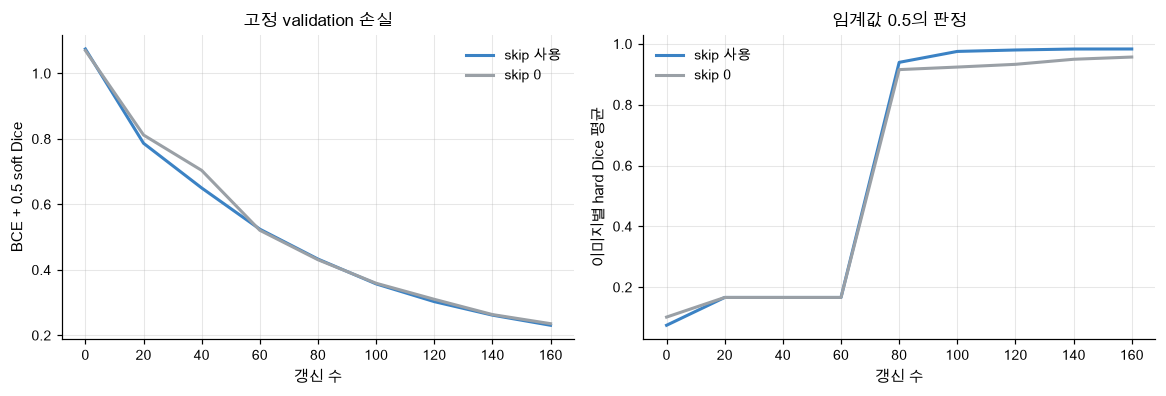

In [49]:
plot_training_curves(skip_history["step"], [skip_history["valid_loss"], zero_history["valid_loss"]], [skip_history["valid_dice"], zero_history["valid_dice"]], ["skip 사용", "skip 0"])

🔍 **확인** · 이 곡선은 실제 validation 결과입니다. 같은 업데이트 수에서도 두 경로의 학습 결과가 다를 수 있습니다. 어느 쪽이 얼마나 좋은지는 아래 고정 test 지표와 실제 mask를 함께 읽습니다. 같은 수의 파라미터 배열을 저장했다는 사실로 유효 모델 크기가 같다고 말하지 않습니다.

In [50]:
# 쓰는 것: evaluate_probability (4절) · sigmoid (1절) · unet_forward (3절)
test_skip_logits = unet_forward(test_images, skip_parameters, True)[0]
test_zero_logits = unet_forward(test_images, zero_parameters, False)[0]
test_skip_probability, test_zero_probability = sigmoid(test_skip_logits), sigmoid(test_zero_logits)
test_skip_metrics = evaluate_probability(test_skip_probability, test_targets)
test_zero_metrics = evaluate_probability(test_zero_probability, test_targets)
background_metrics = evaluate_probability(np.zeros_like(test_targets), test_targets)
print("test 전경 비율 / 빈 이미지 수:", test_targets.mean(), np.sum(test_targets.sum(axis=(1, 2, 3)) == 0))
print("모두 배경:", background_metrics)
print("skip 사용:", test_skip_metrics)
print("skip 0:", test_zero_metrics)
display_indices = np.array([0, 1, 2])
display_labels = [f"test 고정 {i}번" for i in display_indices]

test 전경 비율 / 빈 이미지 수: 0.1343994140625 4
모두 배경: {'pixel_accuracy': 0.8656005859375, 'iou': 0.125, 'dice': 0.125, 'nonempty_iou': 0.0}
skip 사용: {'pixel_accuracy': 0.9927978515625, 'iou': 0.9480639702732827, 'dice': 0.9728359252255612, 'nonempty_iou': 0.9406445374551801}
skip 0: {'pixel_accuracy': 0.98486328125, 'iou': 0.8970728673758778, 'dice': 0.9442460408593905, 'nonempty_iou': 0.8823689912867174}


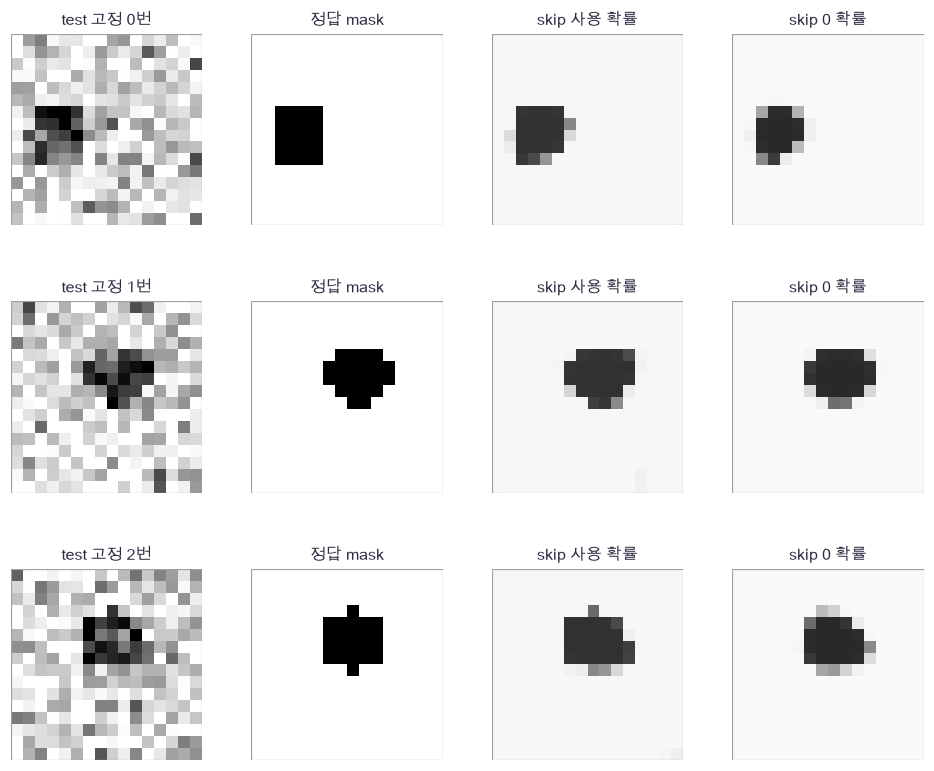

In [51]:
plot_segmentation_predictions(test_images[display_indices, 0], test_targets[display_indices, 0], test_skip_probability[display_indices, 0], test_zero_probability[display_indices, 0], display_labels)

🔍 **확인** · 첫 세 test 관측을 점수를 보고 골라내지 않고 그대로 표시했습니다. 양쪽 빈 mask의 점수를 1로 정했기 때문에 빈 이미지가 많으면 이미지 평균 IoU·Dice가 올라갈 수 있습니다. 그래서 전경 비율·빈 이미지 수와 **정답이 비어 있지 않은 이미지의 IoU**도 함께 보고합니다. 배경이 많은 데이터에서는 화소 정확도 하나만으로 읽지 않습니다.

다음은 학습에 쓰지 않은 **15×17 해상도**에서 전경 크기만 바꾸는 진단입니다. 세 데이터는 같은 생성 seed와 같은 도형 중심·종류를 사용하고 크기 계수만 .55·1·1.35로 바꿉니다. 입력 기울기까지 계산하지만 **파라미터 갱신은 하지 않습니다**. 기울기 norm은 화소 수·손실 평균 분모·현재 예측의 영향을 받는 계산 진단이며 성능 지표가 아닙니다.

In [52]:
# 쓰는 것: hard_scores (4절) · make_shapes (1절) · segmentation_loss (4절) · sigmoid (1절) · unet_backward (3절) · unet_forward (3절)
def inspect_resolution_variant(parameters, size_scale):
    """고정 모델로 홀수15×17의 forward/backward·입력 방향미분 검사. 파라미터 갱신은 없습니다."""
    X, Y = make_shapes(12, 15, 17, 194, size_scale=size_scale)
    logits, cache = unet_forward(X, parameters, True)
    loss, dlogits, terms = segmentation_loss(logits, Y)
    dX, gradients = unet_backward(dlogits, cache)
    assert logits.shape == X.shape, "홀수 해상도도 원래 출력 크기를 유지해야 합니다"
    assert dX.shape == X.shape, "입력 기울기도 원래 해상도로 돌아와야 합니다"
    assert all(np.all(np.isfinite(value)) for value in gradients.values()), "변형에서도 모든 파라미터 미분이 유한해야 합니다"
    direction = np.random.default_rng(195).normal(size=X.shape)
    direction /= np.linalg.norm(direction)
    epsilon = 1e-5
    plus = segmentation_loss(unet_forward(X+epsilon*direction, parameters)[0], Y)[0]
    minus = segmentation_loss(unet_forward(X-epsilon*direction, parameters)[0], Y)[0]
    numeric = (plus-minus)/(2*epsilon)
    analytic = np.sum(dX*direction)
    np.testing.assert_allclose(analytic, numeric, atol=1e-7, rtol=1e-4)  # 검산: 실제 학습 모델과 결합 손실의 방향미분
    return {"foreground": float(Y.mean()), "iou": float(hard_scores(sigmoid(logits), Y)[0].mean()), "input_gradient_norm": float(np.linalg.norm(dX)), "direction_error": float(abs(analytic-numeric))}

In [53]:
# 쓰는 것: skip_parameters (5절)
variant_snapshot = {key: value.copy() for key, value in skip_parameters.items()}
variant_scales = [.55, 1., 1.35]
variant_names = ["15×17 작은 전경", "15×17 기본 전경", "15×17 큰 전경"]
variant_results = [inspect_resolution_variant(skip_parameters, scale) for scale in variant_scales]
for key in skip_parameters:
    np.testing.assert_array_equal(skip_parameters[key], variant_snapshot[key])  # 검산: test 변형 진단이 모델을 갱신하지 않음
variant_foregrounds = [result["foreground"] for result in variant_results]
variant_ious = [result["iou"] for result in variant_results]
variant_gradient_norms = [result["input_gradient_norm"] for result in variant_results]
print("고정 모델의 홀수 해상도·전경 변형:", variant_results)

고정 모델의 홀수 해상도·전경 변형: [{'foreground': 0.04215686274509804, 'iou': 0.9150908595761537, 'input_gradient_norm': 0.03331877799714595, 'direction_error': 1.9754274171307484e-12}, {'foreground': 0.13529411764705881, 'iou': 0.9669642087604272, 'input_gradient_norm': 0.025401517195300413, 'direction_error': 2.353016869890978e-12}, {'foreground': 0.23431372549019608, 'iou': 0.9675850249572235, 'input_gradient_norm': 0.026929210509073025, 'direction_error': 7.535264729893743e-14}]


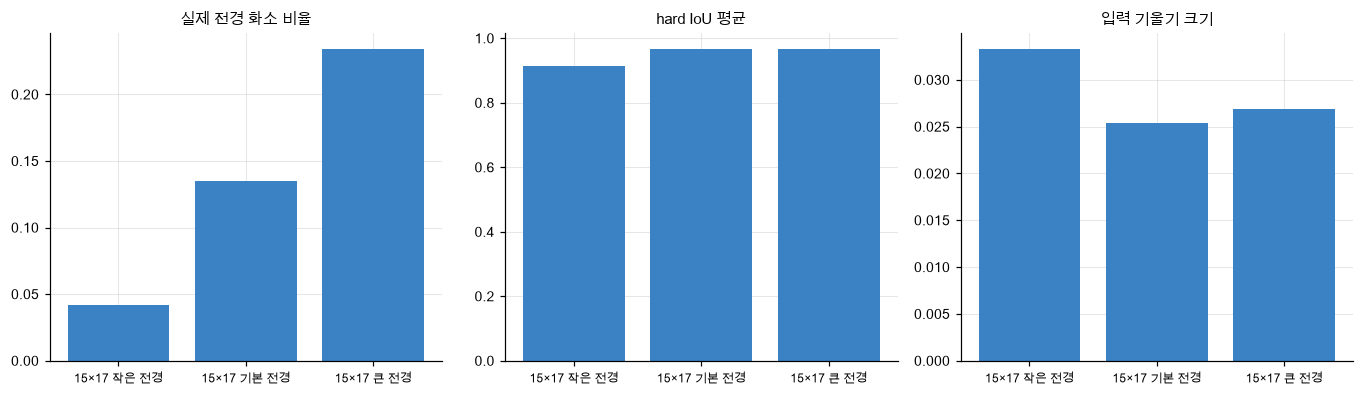

In [54]:
plot_resolution_variants(variant_names, variant_foregrounds, variant_ious, variant_gradient_norms)

🔍 **확인** · 세 조건 모두 실제 forward와 backward를 지나며 입력 방향미분도 중심차분과 대조했습니다. 전경 크기에 따른 IoU 변화와 입력 기울기 크기는 별개의 결과입니다. 이 진단을 본 뒤 모델이나 스텝 수를 바꾸었다면 기존 test 결과를 그대로 최종 성능으로 쓰지 않고 새 평가 계획을 세워야 합니다.

### ✏️ 연습 5 · 저장된 파라미터와 실제 활성 연결을 따로 세기

파라미터 사전의 모든 배열 크기를 더해 `total`을 구하세요. zero-skip의 `Wd` 앞 encoder 채널은 항상 0 입력을 받으므로 그 연결 수를 빼 `active_zero`를 구합니다. 편향과 bottleneck 경로는 활성입니다.

In [55]:
def exercise_parameter_counts(parameters, encoder_channels):
    """연습 5: 저장 수와 zero-skip 활성 수. parameters: 배열 사전 → total, active_zero: 정수."""
    ### 구현할 내용: 모든 배열 size 합, 그리고 Wd 앞 Ce 입력 채널의 size를 뺀 값
    raise NotImplementedError
    return total, active_zero

In [56]:
def check_parameter_counts(candidate):
    """작은 사전의 원소 수를 손으로 셉니다."""
    small = {"Wd": np.zeros((2, 3, 3, 3)), "bd": np.zeros(2), "Wo": np.zeros((1, 2, 1, 1)), "bo": np.zeros(1)}
    total, active = candidate(small, 1)
    assert total == 59, "54+2+2+1 = 59개여야 합니다"
    assert active == 41, "skip 연결 2*1*3*3 = 18개를 빼야 합니다"
    print("파라미터 수: 저장 수와 활성 수의 손계산이 일치합니다.")

run_check(check_parameter_counts, exercise_parameter_counts, hint="total = sum(value.size for value in parameters.values()), active_zero = total - parameters['Wd'][:, :encoder_channels].size")

☐ exercise_parameter_counts: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: total = sum(value.size for value in parameters.values()), active_zero = total - parameters['Wd'][:, :encoder_channels].size


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
total = sum(value.size for value in parameters.values())
active_zero = total - parameters["Wd"][:, :encoder_channels].size
```

</details>

## ✏️ 6. 직접 채워서 확인합니다

A–D에서 합성곱·평균 풀링·빈 mask 규약·encoder의 두 경로를 다시 연결합니다. 한두 줄을 채우고 손계산을 먼저 통과시킨 뒤 본문의 작은 gradcheck 입력을 바꿔 보세요.

### ✏️ 연습 A · 패치 행렬을 출력 채널로 바꾸기

`patches:(NHW,Ckk)`와 `weights:(F,Ckk)`, `bias:(F,)`에서 평탄한 출력 `(NHW,F)`를 만드세요. 출력 채널 F마다 커널 하나가 있습니다.

In [57]:
def exercise_patch_affine(patches, weights, bias):
    """연습 A: 패치 내적. patches:(R,D), weights:(F,D), bias:(F,) → output:(R,F)."""
    ### 구현할 내용: patches @ weights.T + bias
    raise NotImplementedError
    return output

In [58]:
def check_patch_affine(candidate):
    """패치 둘·필터 둘의 내적을 직접 셉니다."""
    patches = np.array([[1., 2., 0.], [0., 1., 3.]])
    weights = np.array([[1., 0., -1.], [0., 2., 1.]])
    np.testing.assert_allclose(candidate(patches, weights, np.array([.5, -1.])), [[1.5, 3.], [-2.5, 4.]])  # 검산: 각 패치·필터 내적에 편향을 더함
    print("패치 행렬곱: 손계산과 일치합니다.")

run_check(check_patch_affine, exercise_patch_affine, hint="output = patches @ weights.T + bias")

☐ exercise_patch_affine: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: output = patches @ weights.T + bias


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
output = patches @ weights.T + bias
```

</details>

### ✏️ 연습 B · 평균 풀링 기울기를 1/4씩 나누고 padding 제거하기

작은 격자 기울기 `G`를 높이·너비 두 번씩 복사한 뒤 4로 나누세요. 마지막 crop은 미리 써 두었습니다. 이는 확대 backward의 합과 반대 역할입니다.

In [59]:
def exercise_average_pool_gradient(G, height, width):
    """연습 B: 2×2 평균의 backward. G:(N,C,h,w) → dX:(N,C,height,width)."""
    ### 구현할 내용: 높이·너비로 두 번씩 복사한 값을 4로 나눕니다.
    raise NotImplementedError
    return expanded[:, :, :height, :width]

In [60]:
def check_average_pool_gradient(candidate):
    """홀수3×3에서 각 블록의 1/4 배분을 확인합니다."""
    G = np.array([[[[4., 8.], [12., 16.]]]])
    actual = candidate(G, 3, 3)
    np.testing.assert_allclose(actual, [[[[1., 1., 2.], [1., 1., 2.], [3., 3., 4.]]]])  # 검산: 복사 후 4로 나누고 우하단 padding 제거
    print("평균 풀링 backward: 손계산과 일치합니다.")

run_check(check_average_pool_gradient, exercise_average_pool_gradient, hint="expanded = np.repeat(np.repeat(G, 2, axis=2), 2, axis=3) / 4")

☐ exercise_average_pool_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: expanded = np.repeat(np.repeat(G, 2, axis=2), 2, axis=3) / 4


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
expanded = np.repeat(np.repeat(G, 2, axis=2), 2, axis=3) / 4
```

</details>

### ✏️ 연습 C · 빈 mask의 hard IoU와 Dice 규약

정수인 교집합 크기·예측 크기·정답 크기를 받아 두 지표를 계산하세요. 합집합 또는 크기 합이 0이면 해당 점수를 1로 둡니다. 이 함수는 평가용이며 미분하지 않습니다.

In [61]:
def exercise_empty_scores(intersection, predicted_size, true_size):
    """연습 C: 이미지 한 장의 hard 점수. 크기 세 개 → iou,dice 숫자."""
    union = predicted_size+true_size-intersection
    total = predicted_size+true_size
    ### 구현할 내용: 분모가 0이면 1, 아니면 intersection/union과 2*intersection/total
    raise NotImplementedError
    return iou, dice

In [62]:
def check_empty_scores(candidate):
    """양쪽 빈 경우·한쪽 빈 경우·부분 겹침의 정의를 확인합니다."""
    np.testing.assert_allclose(candidate(0, 0, 0), [1., 1.])  # 검산: 양쪽 모두 비면 완전 일치
    np.testing.assert_allclose(candidate(0, 2, 0), [0., 0.])  # 검산: 예측만 있으면 겹침 없음
    np.testing.assert_allclose(candidate(0, 0, 2), [0., 0.])  # 검산: 정답만 있어도 겹침 없음
    np.testing.assert_allclose(candidate(1, 2, 1), [.5, 2/3])  # 검산: 교집합1·합집합2
    print("빈 mask 규약: 손계산과 일치합니다.")

run_check(check_empty_scores, exercise_empty_scores, hint="iou = intersection/union if union else 1., dice = 2*intersection/total if total else 1.")

☐ exercise_empty_scores: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: iou = intersection/union if union else 1., dice = 2*intersection/total if total else 1.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
iou = intersection/union if union else 1.
dice = 2*intersection/total if total else 1.
```

</details>

### ✏️ 연습 D · encoder에 돌아온 두 경로를 더한 뒤 미분하기

`E=tanh(Z_e)`에서 두 경로의 상류 기울기 `from_down`, `from_skip`을 합하고 tanh 미분을 곱하세요. 세 입력의 shape는 같습니다.

In [63]:
def exercise_encoder_gradient(E, from_down, from_skip):
    """연습 D: 두 경로 합과 tanh 연쇄법칙. 세 (N,C,H,W) → dZ_e: 같은 shape."""
    ### 구현할 내용: (from_down + from_skip) * (1 - E**2)
    raise NotImplementedError
    return dZ_e

In [64]:
def check_encoder_gradient(candidate):
    """두 경로가 합해지고, 상쇄될 때 0이 되는지 손계산합니다."""
    E = np.array([[[[0., .5]]]])
    down = np.array([[[[2., 4.]]]])
    skip = np.array([[[[3., -2.]]]])
    np.testing.assert_allclose(candidate(E, down, skip), [[[[5., 1.5]]]])  # 검산: (2+3)*1, (4-2)*.75
    np.testing.assert_allclose(candidate(E, down, -down), 0.)  # 검산: 서로 반대인 기여는 상쇄
    print("encoder 두 경로: 손계산과 일치합니다.")

run_check(check_encoder_gradient, exercise_encoder_gradient, hint="dZ_e = (from_down + from_skip) * (1-E**2)")

☐ exercise_encoder_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: dZ_e = (from_down + from_skip) * (1-E**2)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dZ_e = (from_down + from_skip) * (1-E**2)
```

</details>

### ✏️ 준비도 질문 · 네 가지를 따로 확인합니다

- **설명:** 이미지 분류·입력 복원·화소 분할의 정답이 어떻게 다른지, encoder–decoder 사이의 skip이 전달하는 정보는 무엇인지 말할 수 있나요? → 1·3절
- **수식:** $H,W$가 홀수일 때 pool·up의 shape, padding을 포함한 분모 4, BCE의 $NHW$와 soft Dice의 $N$ 분모, 빈 hard mask 규약을 쓸 수 있나요? → 2·4절
- **구현:** concatenate를 채널 분할로 미분하고, encoder의 두 기여를 합해 모든 가중치와 입력까지 역전파할 수 있나요? → 3절, 연습 A·B·D
- **변형 검산:** 15×17을 다른 홀수 해상도로 바꾸고 크기·기울기를 검산할 수 있나요? 전경 비율을 바꿀 때 화소 정확도·빈 mask·nonempty IoU를 구분하고, 평가 중 파라미터를 갱신하지 않았음을 확인할 수 있나요? → 5절, 연습 C

### 📎 다음 연결

이 노트북의 학습 목적은 화소별 전경 분류입니다. 같은 encoder–decoder 구조에 이미지 복원이나 잡음 예측 목표를 붙이면 출력의 의미와 손실이 바뀝니다. 구조·목적·optimizer·학습 후 사용을 따로 적은 뒤 18b 검출, 34–35 diffusion의 예측기로 연결해 보세요.